# Final Project: Boston Housing

Estimated time needed: **60** minutes

Import the required libraries we need for the lab.

In [ ]:
import piplite
await piplite.install(['numpy'],['pandas'])
await piplite.install(['seaborn'])

In [ ]:
import pandas as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

Read the dataset in the csv file from the URL

In [ ]:
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
resp = await fetch(URL)
boston_url = io.BytesIO((await resp.arrayBuffer()).to_py())

In [ ]:
boston_df=pd.read_csv(boston_url)

Add your code below following the instructions given in the course to complete the peer graded assignment

## Project Scenario

I am a Data Scientist at a housing agency in Boston, MA, working with housing data collected by the U.S. Census Service. Upper management wants to understand four things:

1. Whether there is a significant difference in the median value of houses bounded by the Charles River versus those that are not.
2. How median house values vary with the proportion of owner-occupied units built before 1940.
3. Whether there is a relationship between Nitric Oxide (NOX) concentrations and the proportion of non-retail business acres per town.
4. The impact of an additional weighted distance to the five Boston employment centers on the median value of owner-occupied homes.

**Key variables used in this analysis**

| Variable | Description |
|---|---|
| CHAS | Charles River dummy variable (1 if the tract bounds the river, 0 otherwise) |
| NOX | Nitric oxide concentration (parts per 10 million) |
| INDUS | Proportion of non-retail business acres per town |
| AGE | Proportion of owner-occupied units built before 1940 |
| DIS | Weighted distances to five Boston employment centers |
| PTRATIO | Pupil-teacher ratio by town |
| MEDV | Median value of owner-occupied homes in $1000s |

All hypothesis tests below use a significance level of **α = 0.05**.

## Task 1: Become Familiar with the Dataset

### Exercise 1: Display the first five rows

In [ ]:
boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


The dataset loaded correctly. The first column (`Unnamed: 0`) is just a row index carried over from the CSV file, so it is excluded from the analysis.

### Exercise 2: Check the data type of each column

In [ ]:
boston_df.dtypes

Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS            int64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD             int64
TAX             int64
PTRATIO       float64
LSTAT         float64
MEDV          float64
dtype: object

Every column is numeric (integer or float), so no type conversion is needed before running statistics. `CHAS` is stored as an integer, but it is really a yes/no category (0 = not on the river, 1 = on the river).

### Exercise 3: Check the size of the dataset and summary statistics

In [ ]:
print('Rows, columns:', boston_df.shape)
boston_df.describe()

Rows, columns: (506, 14)


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


There are 506 census tracts and 14 columns. Median home values (`MEDV`) average about \$22,500, with a median of about \$21,200, and range from \$5,000 to \$50,000. The fact that the mean is higher than the median is an early hint that a few high-value homes pull the average up.

### Exercise 4: Check for missing values

In [ ]:
boston_df.isnull().sum()

Unnamed: 0    0
CRIM          0
ZN            0
INDUS         0
CHAS          0
NOX           0
RM            0
AGE           0
DIS           0
RAD           0
TAX           0
PTRATIO       0
LSTAT         0
MEDV          0
dtype: int64

There are no missing values in any column, so no rows need to be dropped or filled in.

### Exercise 5: Check for duplicate entries

In [ ]:
print('Duplicate rows:', boston_df.duplicated().sum())

Duplicate rows: 0


There are no duplicate rows, so each record represents a unique census tract.

### Exercise 6: Compute the correlation matrix

In [ ]:
boston_df.drop(columns=['Unnamed: 0']).corr().round(3)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
CRIM,1.000,-0.200,0.407,-0.056,0.421,-0.219,0.353,-0.380,0.626,0.583,0.290,0.456,-0.388
ZN,-0.200,1.000,-0.534,-0.043,-0.517,0.312,-0.570,0.664,-0.312,-0.315,-0.392,-0.413,0.360
INDUS,0.407,-0.534,1.000,0.063,0.764,-0.392,0.645,-0.708,0.595,0.721,0.383,0.604,-0.484
CHAS,-0.056,-0.043,0.063,1.000,0.091,0.091,0.087,-0.099,-0.007,-0.036,-0.122,-0.054,0.175
NOX,0.421,-0.517,0.764,0.091,1.000,-0.302,0.731,-0.769,0.611,0.668,0.189,0.591,-0.427
RM,-0.219,0.312,-0.392,0.091,-0.302,1.000,-0.240,0.205,-0.210,-0.292,-0.356,-0.614,0.695
AGE,0.353,-0.570,0.645,0.087,0.731,-0.240,1.000,-0.748,0.456,0.506,0.262,0.602,-0.377
DIS,-0.380,0.664,-0.708,-0.099,-0.769,0.205,-0.748,1.000,-0.495,-0.534,-0.232,-0.497,0.250
RAD,0.626,-0.312,0.595,-0.007,0.611,-0.210,0.456,-0.495,1.000,0.910,0.465,0.489,-0.382
TAX,0.583,-0.315,0.721,-0.036,0.668,-0.292,0.506,-0.534,0.910,1.000,0.461,0.544,-0.469


Looking at the `MEDV` column, the strongest relationships with home value are the share of lower-status population (`LSTAT`, r ≈ −0.74) and average number of rooms (`RM`, r ≈ 0.70). Among the variables management asked about, `NOX` and `INDUS` are strongly positively correlated with each other (r ≈ 0.76), `AGE` is negatively related to home value (r ≈ −0.38), and `DIS` has a weak positive relationship with home value (r ≈ 0.25). These are tested formally in Task 3.

### Exercise 7: Display the entire DataFrame

In [ ]:
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(boston_df)

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0,0.5380,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0,0.4690,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0,0.4690,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0,0.4580,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0,0.4580,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
5,5,0.02985,0.0,2.18,0,0.4580,6.430,58.7,6.0622,3,222,18.7,5.21,28.7
6,6,0.08829,12.5,7.87,0,0.5240,6.012,66.6,5.5605,5,311,15.2,12.43,22.9
7,7,0.14455,12.5,7.87,0,0.5240,6.172,96.1,5.9505,5,311,15.2,19.15,27.1
8,8,0.21124,12.5,7.87,0,0.5240,5.631,100.0,6.0821,5,311,15.2,29.93,16.5
9,9,0.17004,12.5,7.87,0,0.5240,6.004,85.9,6.5921,5,311,15.2,17.10,18.9


Showing all 506 rows confirms the data is complete and consistent from top to bottom, with no blank or malformed records.

## Task 2: Generate Descriptive Statistics and Visualizations

### Exercise 8: Boxplot for the Median value of owner-occupied homes (MEDV)

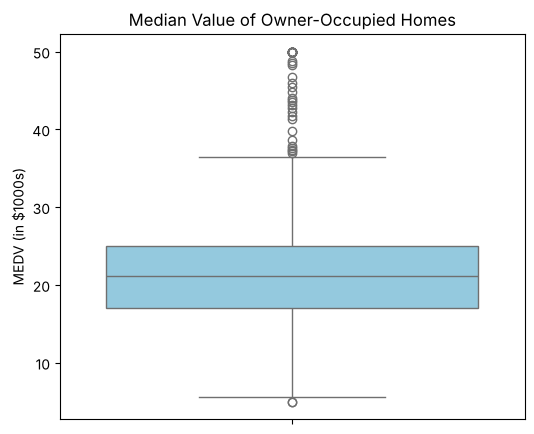

In [ ]:
pyplot.figure(figsize=(6, 5))
ax = sns.boxplot(y='MEDV', data=boston_df, color='skyblue')
ax.set_title('Median Value of Owner-Occupied Homes')
ax.set_ylabel('MEDV (in $1000s)')
pyplot.show()

**Interpretation:** The middle 50% of homes are valued between about \$17,000 and \$25,000, with a median of about \$21,200. There are many outliers above the upper whisker (homes worth more than roughly \$37,000), including a cluster at the \$50,000 maximum, which suggests values were capped at \$50,000 when the data was collected. For management, this means most of the market sits in a fairly narrow middle range, while a small group of high-value neighborhoods pulls the average upward.

### Exercise 9: Bar plot for the Charles River variable (CHAS)

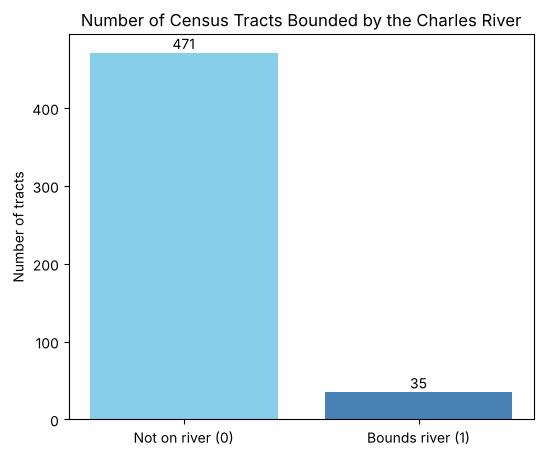

In [ ]:
chas_counts = boston_df['CHAS'].value_counts().sort_index()
pyplot.figure(figsize=(6, 5))
bars = pyplot.bar(['Not on river (0)', 'Bounds river (1)'], chas_counts.values, color=['skyblue', 'steelblue'])
for bar, value in zip(bars, chas_counts.values):
    pyplot.text(bar.get_x() + bar.get_width() / 2, value + 5, str(value), ha='center')
pyplot.title('Number of Census Tracts Bounded by the Charles River')
pyplot.ylabel('Number of tracts')
pyplot.show()

**Interpretation:** Only 35 of the 506 tracts (about 7%) are bounded by the Charles River, while 471 (about 93%) are not. Riverfront property is rare in this dataset. That small group size is worth keeping in mind when comparing the two groups in Task 3.

### Exercise 10: Boxplot for MEDV vs. AGE group

The `AGE` variable is grouped into three categories: 35 years and younger, between 35 and 70 years, and 70 years and older.

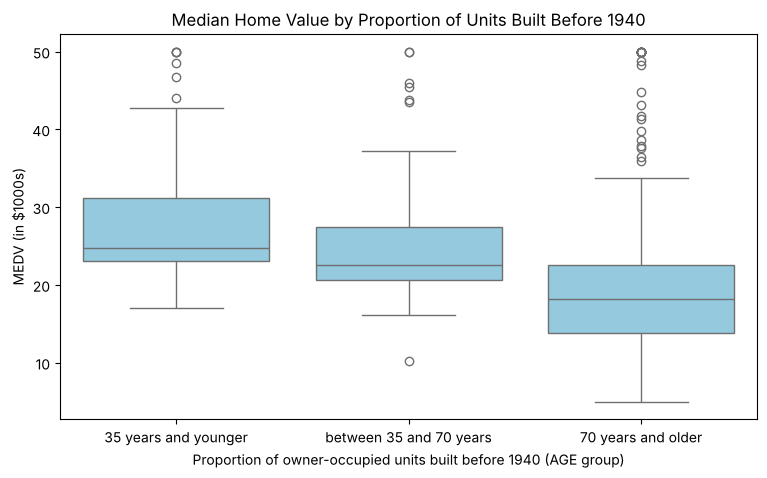

,count,mean,median
AGE_GROUP,,,
35 years and younger,91,27.78,24.8
between 35 and 70 years,128,24.95,22.6
70 years and older,287,19.79,18.2


In [ ]:
boston_df['AGE_GROUP'] = pd.cut(boston_df['AGE'], bins=[0, 35, 70, 100],
                                labels=['35 years and younger', 'between 35 and 70 years', '70 years and older'])

pyplot.figure(figsize=(9, 5))
ax = sns.boxplot(x='AGE_GROUP', y='MEDV', data=boston_df, color='skyblue')
ax.set_title('Median Home Value by Proportion of Units Built Before 1940')
ax.set_xlabel('Proportion of owner-occupied units built before 1940 (AGE group)')
ax.set_ylabel('MEDV (in $1000s)')
pyplot.show()

boston_df.groupby('AGE_GROUP')['MEDV'].agg(['count', 'mean', 'median']).round(2)

**Interpretation:** Home values go down as the share of older housing goes up. Tracts where 35% or fewer of the homes were built before 1940 have the highest median value (about \$24,800). Tracts in the 35–70% range sit in the middle (about \$22,600), and tracts where more than 70% of homes are older have the lowest median (about \$18,200). The oldest group is also the largest (287 tracts) and has many high-value outliers, meaning some older neighborhoods still command premium prices. Overall, newer housing stock is associated with higher home values.

### Exercise 11: Scatter plot of Nitric Oxide concentration (NOX) vs. non-retail business acres (INDUS)

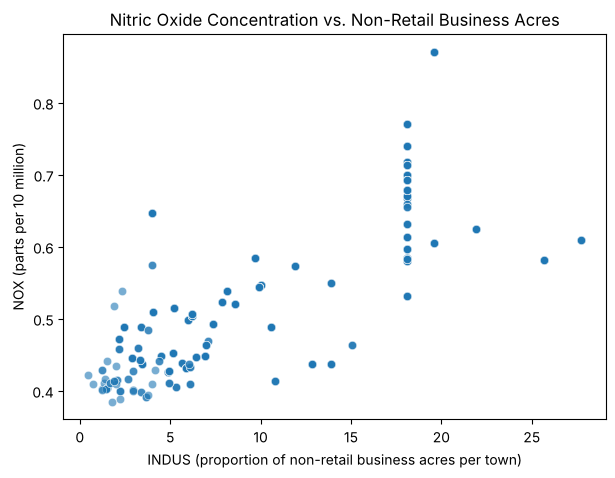

In [ ]:
pyplot.figure(figsize=(7, 5))
ax = sns.scatterplot(x='INDUS', y='NOX', data=boston_df, alpha=0.6)
ax.set_title('Nitric Oxide Concentration vs. Non-Retail Business Acres')
ax.set_xlabel('INDUS (proportion of non-retail business acres per town)')
ax.set_ylabel('NOX (parts per 10 million)')
pyplot.show()

**Interpretation:** There is a clear positive relationship: towns with a larger share of non-retail business (industrial) land tend to have higher nitric oxide concentrations. The points rise from the lower left to the upper right, with some vertical clustering at specific INDUS values, since many tracts in the same town share the same INDUS figure. This suggests industrial land use is linked to poorer air quality, which is tested formally with a Pearson correlation in Task 3.

### Exercise 12: Histogram for the pupil-to-teacher ratio (PTRATIO)

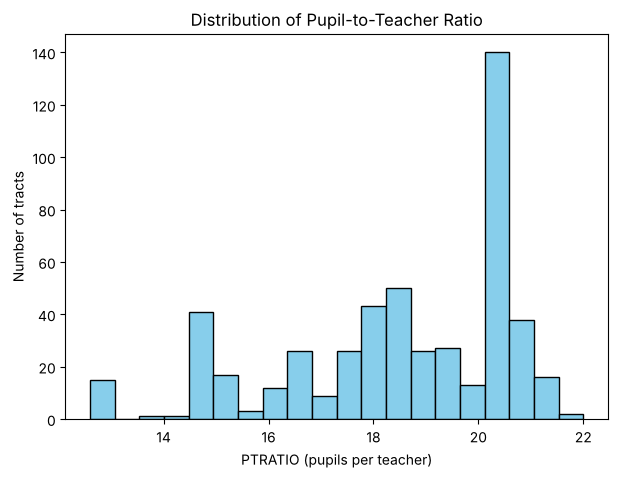

Mean: 18.46
Median: 19.05
Most common value: 20.2
Skewness: -0.8


In [ ]:
pyplot.figure(figsize=(7, 5))
pyplot.hist(boston_df['PTRATIO'], bins=20, color='skyblue', edgecolor='black')
pyplot.title('Distribution of Pupil-to-Teacher Ratio')
pyplot.xlabel('PTRATIO (pupils per teacher)')
pyplot.ylabel('Number of tracts')
pyplot.show()

print('Mean:', round(boston_df['PTRATIO'].mean(), 2))
print('Median:', boston_df['PTRATIO'].median())
print('Most common value:', boston_df['PTRATIO'].mode()[0])
print('Skewness:', round(boston_df['PTRATIO'].skew(), 2))

**Interpretation:** Pupil-to-teacher ratios range from about 12.6 to 22, with most towns between 17 and 21 students per teacher. The distribution is skewed to the left (skewness ≈ −0.80): the mean (18.5) is below the median (19.05) because a smaller number of towns have notably low ratios. The tallest bar is at 20.2, which is the single most common value and accounts for a large spike of tracts. For management, this means most neighborhoods have similar, fairly high class sizes, and only a few areas offer noticeably smaller ones.

## Task 3: Use the Appropriate Tests to Answer the Questions Provided

For each question, I state the hypotheses, run the test, and draw a conclusion using **α = 0.05**.

### Question 1: Is there a significant difference in median value of houses bounded by the Charles River or not?

**Test:** Independent samples t-test (comparing the mean of two independent groups).

- **H₀:** There is no difference in the mean median home value between houses bounded by the Charles River and those that are not (μ₁ = μ₂).
- **H₁:** There is a difference in the mean median home value between the two groups (μ₁ ≠ μ₂).

### Exercise 13: Levene's test for equality of variances

Before running the t-test, Levene's test checks whether the two groups have equal variances. This decides which version of the t-test to use.

- **H₀:** The variances of the two groups are equal.
- **H₁:** The variances of the two groups are not equal.

In [ ]:
river = boston_df[boston_df['CHAS'] == 1]['MEDV']
no_river = boston_df[boston_df['CHAS'] == 0]['MEDV']

scipy.stats.levene(river, no_river, center='mean')

LeveneResult(statistic=np.float64(8.75190489604598), pvalue=np.float64(0.0032381193676394252))

**Conclusion:** The p-value (≈ 0.003) is less than 0.05, so we reject the null hypothesis. The two groups do **not** have equal variances. For that reason, the t-test below uses `equal_var=False` (Welch's t-test), which does not assume equal variances.

### Exercise 14: T-test for independent samples

In [ ]:
print(boston_df.groupby('CHAS')['MEDV'].agg(['count', 'mean', 'median']).round(2))
print()
print('Welch t-test (unequal variances):', scipy.stats.ttest_ind(river, no_river, equal_var=False))
print('Standard t-test (equal variances, for comparison):', scipy.stats.ttest_ind(river, no_river, equal_var=True))

      count   mean  median
CHAS                      
0       471  22.09    20.9
1        35  28.44    23.3

Welch t-test (unequal variances): TtestResult(statistic=np.float64(3.113291312794837), pvalue=np.float64(0.003567170098137519), df=np.float64(36.876408797611994))
Standard t-test (equal variances, for comparison): TtestResult(statistic=np.float64(3.996437466090509), pvalue=np.float64(7.390623170519907e-05), df=np.float64(504.0))


**Conclusion:** The p-value (≈ 0.0036) is less than 0.05, so we reject the null hypothesis. There is a statistically significant difference in median home values based on whether a house is bounded by the Charles River. Riverfront homes average about \$28,400, compared to about \$22,100 for homes away from the river, a difference of roughly \$6,300. The standard t-test gives the same conclusion (p ≈ 0.00007), so the result holds either way.

**For management:** Being on the Charles River is associated with meaningfully higher home values.

### Question 2: Is there a difference in median values of houses for each proportion of owner-occupied units built before 1940?

**Test:** One-way ANOVA (comparing the means of more than two groups), using the three AGE groups created in Exercise 10.

- **H₀:** The mean median home value is the same across all three AGE groups (μ₁ = μ₂ = μ₃).
- **H₁:** At least one AGE group has a different mean median home value.

### Exercise 15: One-way ANOVA

In [ ]:
young = boston_df[boston_df['AGE_GROUP'] == '35 years and younger']['MEDV']
middle = boston_df[boston_df['AGE_GROUP'] == 'between 35 and 70 years']['MEDV']
old = boston_df[boston_df['AGE_GROUP'] == '70 years and older']['MEDV']

print('Levene test (equal variances check):', scipy.stats.levene(young, middle, old, center='mean'))

f_statistic, p_value = scipy.stats.f_oneway(young, middle, old)
print('F-statistic: {0}, P-value: {1}'.format(f_statistic, p_value))

Levene test (equal variances check): LeveneResult(statistic=np.float64(2.7806200293748304), pvalue=np.float64(0.06295337343258786))
F-statistic: 36.40764999196599, P-value: 1.7105011022701404e-15


**Conclusion:** Levene's test p-value (≈ 0.063) is greater than 0.05, so we can assume equal variances, which supports using ANOVA. The ANOVA p-value (≈ 1.7 × 10⁻¹⁵) is far below 0.05, so we reject the null hypothesis. At least one AGE group has a significantly different mean home value. Combined with the boxplot in Exercise 10, the pattern is clear: neighborhoods with a higher share of homes built before 1940 have lower median home values.

**For management:** The age of a neighborhood's housing stock matters. Areas dominated by older homes tend to be valued lower.

### Question 3: Can we conclude that there is no relationship between Nitric oxide concentrations and proportion of non-retail business acres per town?

**Test:** Pearson correlation (relationship between two continuous variables).

- **H₀:** There is no relationship between NOX and INDUS (ρ = 0).
- **H₁:** There is a relationship between NOX and INDUS (ρ ≠ 0).

### Exercise 16: Pearson correlation

In [ ]:
scipy.stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])

PearsonRResult(statistic=np.float64(0.7636514469209154), pvalue=np.float64(7.913361061239639e-98))

**Conclusion:** The p-value (≈ 7.9 × 10⁻⁹⁸) is far less than 0.05, so we reject the null hypothesis. We **cannot** conclude that there is no relationship. The correlation coefficient of about 0.76 shows a strong positive relationship: as the proportion of non-retail business acres increases, nitric oxide concentrations increase too. This matches the upward trend in the scatter plot from Exercise 11.

**For management:** Industrial land use is strongly linked to higher air pollution, which is a relevant factor when evaluating neighborhoods.

### Question 4: What is the impact of an additional weighted distance to the five Boston employment centres on the median value of owner-occupied homes?

**Test:** Simple linear regression, with DIS as the independent variable and MEDV as the dependent variable.

- **H₀:** Weighted distance to the employment centers has no effect on median home value (β₁ = 0).
- **H₁:** Weighted distance to the employment centers does affect median home value (β₁ ≠ 0).

### Exercise 17: Regression analysis

In [ ]:
X = boston_df['DIS']
y = boston_df['MEDV']
X = sm.add_constant(X)

model = sm.OLS(y, X).fit()
predictions = model.predict(X)
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        15:54:16   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.000      16.784      19.996
DIS            1.0916      0.188      5.795      0.000       0.722       1.462
==============================================================================
Omnibus:                      139.779   Durbin-Watson:                   0.570
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              305.104
Skew:                           1.466   Prob(JB):                     5.59e-67
Kurtosis:                       5.424   Cond. No.                         9.32
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Conclusion:** The p-value for DIS (≈ 1.2 × 10⁻⁸) is less than 0.05, so we reject the null hypothesis. Distance to the employment centers has a statistically significant effect on home value.

The coefficient for DIS is about **1.09**. Because MEDV is measured in \$1000s, this means each additional unit of weighted distance from the five Boston employment centers is associated with an increase of about **\$1,092** in median home value. The 95% confidence interval for this effect runs from about \$720 to \$1,460.

The R-squared is about 0.062, meaning distance alone explains only about 6% of the variation in home values. Distance is a real factor, but other features (such as number of rooms and neighborhood income levels) matter much more.

**For management:** Homes farther from the employment centers tend to be worth slightly more, likely reflecting quieter, less industrial suburbs. But distance by itself is a weak predictor and should not be used alone to estimate home values.

## Summary of Findings for Management

| Question | Test | Result | Conclusion |
|---|---|---|---|
| Charles River vs. home value | Welch t-test | p ≈ 0.0036 | Riverfront homes are worth significantly more (about \$6,300 higher on average) |
| Older housing stock vs. home value | One-way ANOVA | p ≈ 1.7 × 10⁻¹⁵ | Areas with more pre-1940 homes have significantly lower values |
| NOX vs. industrial land | Pearson correlation | r ≈ 0.76, p ≈ 7.9 × 10⁻⁹⁸ | Strong positive relationship: more industrial land, more air pollution |
| Distance to employment centers vs. home value | Linear regression | β ≈ 1.09, p ≈ 1.2 × 10⁻⁸ | Each extra unit of distance adds about \$1,092, but distance explains only about 6% of value |